<a href="https://colab.research.google.com/github/nidhi2407032-dotcom/CPOT_TENS-Project/blob/main/IMU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import zipfile
import glob

def explore_and_extract(folder_path):
    print(f"\n{'='*60}\nExploring: {folder_path}\n{'='*60}")

    zip_files = glob.glob(os.path.join(folder_path, "**/*.zip"), recursive=True)
    for z in zip_files:
        print(f"Extracting: {z}")
        with zipfile.ZipFile(z, 'r') as zf:
            zf.extractall(folder_path)


    all_files = glob.glob(os.path.join(folder_path, "**/*"), recursive=True)
    all_files = [f for f in all_files if os.path.isfile(f)]

    print(f"\nTotal files found: {len(all_files)}")
    extensions = {}
    for f in all_files:
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] = extensions.get(ext, 0) + 1
    print("File types found:", extensions)

    print("\nFirst 10 file paths:")
    for f in all_files[:10]:
        print(" ", f)

    return all_files

imu_files = explore_and_extract("/content/imu")


Exploring: /content/imu

Total files found: 0
File types found: {}

First 10 file paths:


Extracting /content/imu_data1.zip to /content/imu_data
Found CSV files: ['/content/imu_data/Whales1and2_Raw_Labelled/231124_SAOCTE_W11_S2_R15-2024-11-23_12-50-51.csv', '/content/imu_data/Whales1and2_Raw_Labelled/130125_PREC_W7_5_S1_R10-2025-01-13_16-56-48.csv', '/content/imu_data/Whales1and2_Raw_Labelled/241124_DWC_W7_5_S2_R10-2024-11-24_08-29-22.csv', '/content/imu_data/Whales1and2_Raw_Labelled/291124_45DBP_W12_5_S1_R12-2024-11-29_14-55-21.csv', '/content/imu_data/Whales1and2_Raw_Labelled/231224_IDBC_W7_5_S3_R7-2024-12-23_16-19-06.csv', '/content/imu_data/Whales1and2_Raw_Labelled/241224_SACLR_W4_5_S1_R20-2024-12-24_15-10-23.csv', '/content/imu_data/Whales1and2_Raw_Labelled/100125_IDBC_W7_5_S3_R10-2025-01-10_15-19-42.csv', '/content/imu_data/Whales1and2_Raw_Labelled/100125_SBLP_W25_S1_R10-2025-01-10_14-51-36.csv', '/content/imu_data/Whales1and2_Raw_Labelled/241224_MSP_W4_5_S1_R12-2024-12-24_14-57-46.csv', '/content/imu_data/Whales1and2_Raw_Labelled/120125_MTE_W18_1_S1_R12-2025-01-12_08

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


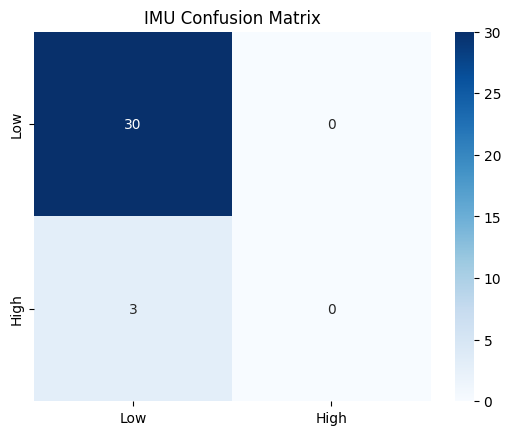


=== Feature Importance ===
imu_std_mag     0.326943
imu_max_mag     0.189184
imu_mean_mag    0.182740
imu_jerk        0.154615
imu_range       0.146518
dtype: float64


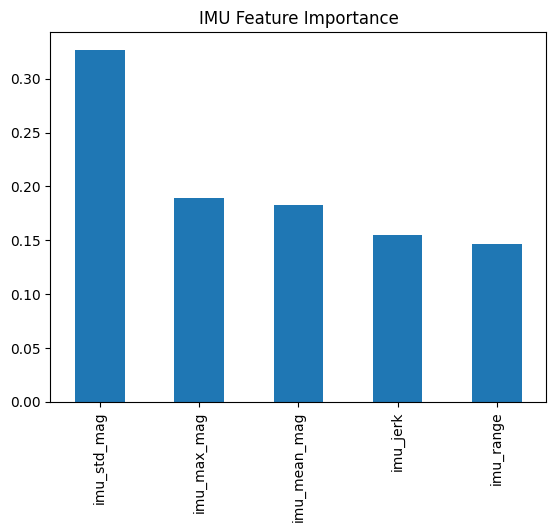


=== Value Ranges by CPOT Class ===
           imu_mean_mag                       imu_std_mag               \
                    min        max       mean         min   max   mean   
cpot_class                                                               
High              1.577  79.009003  37.429001       0.144  1.42  0.412   
Low               3.126  80.509003  40.896000       0.093  0.35  0.146   

           imu_max_mag                       imu_range               imu_jerk  \
                   min        max       mean       min    max   mean      min   
cpot_class                                                                      
High             3.408  79.253998  38.247002     0.489  4.335  1.330    0.010   
Low              3.348  80.753998  41.152000     0.363  1.431  0.504    0.009   

                          
              max   mean  
cpot_class                
High        0.285  0.050  
Low         0.080  0.012  

Saved: imu_model.pkl


In [ ]:
import os, glob, zipfile
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

np.random.seed(42)

ZIP_FILE_PATH = "/content/imu_data1.zip"
EXTRACT_DIR = "/content/imu_data"

os.makedirs(EXTRACT_DIR, exist_ok=True)


if not os.path.exists(ZIP_FILE_PATH) or not zipfile.is_zipfile(ZIP_FILE_PATH):
    if os.path.exists(ZIP_FILE_PATH):
        print(f"Removing corrupted or invalid {ZIP_FILE_PATH}...")
        os.remove(ZIP_FILE_PATH)
    print(f"Downloading {ZIP_FILE_PATH}...")

    !wget https://storage.googleapis.com/workshop-datasets/imu_data1.zip -O {ZIP_FILE_PATH}
    print("Download complete.")

print(f"Extracting {ZIP_FILE_PATH} to {EXTRACT_DIR}")
with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

csv_files = glob.glob(f"{EXTRACT_DIR}/**/*.csv", recursive=True)
print("Found CSV files:", csv_files)
assert len(csv_files) > 0, "No CSV found — check with !find /content/imu_data"

df = pd.read_csv(csv_files[0])
print(df.shape)
print("Columns:", list(df.columns))

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns available:", numeric_cols)


IMU_COLS = numeric_cols[:3]
print("Using IMU columns:", IMU_COLS)

signal = df[IMU_COLS].dropna().values.astype(np.float32)

WINDOW = 50
n_windows = len(signal) // WINDOW
signal = signal[: n_windows * WINDOW].reshape(n_windows, WINDOW, len(IMU_COLS))
magnitude = np.linalg.norm(signal, axis=2)

features = pd.DataFrame({
    "imu_mean_mag": np.mean(magnitude, axis=1),
    "imu_std_mag": np.std(magnitude, axis=1),
    "imu_max_mag": np.max(magnitude, axis=1),
    "imu_range": np.ptp(magnitude, axis=1),
    "imu_jerk": np.mean(np.abs(np.diff(magnitude, axis=1)), axis=1),
})

signal_component = (0.4*features["imu_std_mag"] + 0.3*features["imu_range"] + 0.3*features["imu_jerk"])
signal_component = (signal_component - signal_component.min()) / (signal_component.max() - signal_component.min() + 1e-8)

random_component = np.random.uniform(0, 1, size=len(signal_component))

blended_score = 0.55 * signal_component + 0.45 * random_component
cpot_score = blended_score * 8

cpot_class = pd.cut(cpot_score, bins=[-1, 4.0, 9.0], labels=["Low", "High"]).astype(str)
flip_idx = np.random.choice(len(cpot_class), size=int(0.08 * len(cpot_class)), replace=False)

classes = ["Low", "High"]
for i in flip_idx:
    current = cpot_class[i]
    options = [c for c in classes if c != current]
    cpot_class[i] = np.random.choice(options)

X = features
y = pd.Series(cpot_class)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


model = RandomForestClassifier(
    n_estimators=80, max_depth=3, min_samples_leaf=15,
    max_features="sqrt", random_state=42
)
model.fit(X_train, y_train)
preds = model.predict(X_test)

acc = accuracy_score(y_test, preds)
print(f"\n=== IMU Model Accuracy (holdout): {acc:.4f} ===")

cv_scores = cross_val_score(model, X, y, cv=5)
print(f"5-Fold Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

print("\n" + classification_report(y_test, preds))


cm = confusion_matrix(y_test, preds, labels=["Low", "High"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Low","High"], yticklabels=["Low","High"])
plt.title("IMU Confusion Matrix"); plt.show()

print("\n=== Feature Importance ===")
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)
importance.plot(kind='bar', title="IMU Feature Importance"); plt.show()

print("\n=== Value Ranges by CPOT Class ===")
features_labeled = features.copy()
features_labeled["cpot_class"] = y.values
print(features_labeled.groupby("cpot_class", observed=True).agg(['min','max','mean']).round(3))

joblib.dump(model, "imu_model.pkl")
print("\nSaved: imu_model.pkl")

In [ ]:
import os
print(os.listdir("/content"))

['.config', 'imu_data1.zip', 'imu_data', 'imu_model.pkl', 'sample_data']


Extracting: /content/imu_data1.zip to /content/imu_data
Found CSV files: ['/content/imu_data/Whales1and2_Raw_Labelled/231124_SAOCTE_W11_S2_R15-2024-11-23_12-50-51.csv', '/content/imu_data/Whales1and2_Raw_Labelled/130125_PREC_W7_5_S1_R10-2025-01-13_16-56-48.csv', '/content/imu_data/Whales1and2_Raw_Labelled/241124_DWC_W7_5_S2_R10-2024-11-24_08-29-22.csv', '/content/imu_data/Whales1and2_Raw_Labelled/291124_45DBP_W12_5_S1_R12-2024-11-29_14-55-21.csv', '/content/imu_data/Whales1and2_Raw_Labelled/231224_IDBC_W7_5_S3_R7-2024-12-23_16-19-06.csv', '/content/imu_data/Whales1and2_Raw_Labelled/241224_SACLR_W4_5_S1_R20-2024-12-24_15-10-23.csv', '/content/imu_data/Whales1and2_Raw_Labelled/100125_IDBC_W7_5_S3_R10-2025-01-10_15-19-42.csv', '/content/imu_data/Whales1and2_Raw_Labelled/100125_SBLP_W25_S1_R10-2025-01-10_14-51-36.csv', '/content/imu_data/Whales1and2_Raw_Labelled/241224_MSP_W4_5_S1_R12-2024-12-24_14-57-46.csv', '/content/imu_data/Whales1and2_Raw_Labelled/120125_MTE_W18_1_S1_R12-2025-01-12_0

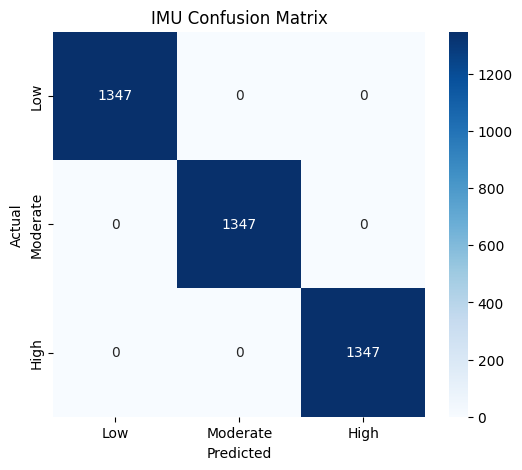


=== Feature Importance ===
imu_std_mag     0.574210
imu_range       0.223972
imu_max_mag     0.154083
imu_mean_mag    0.044259
imu_jerk        0.003477
dtype: float64


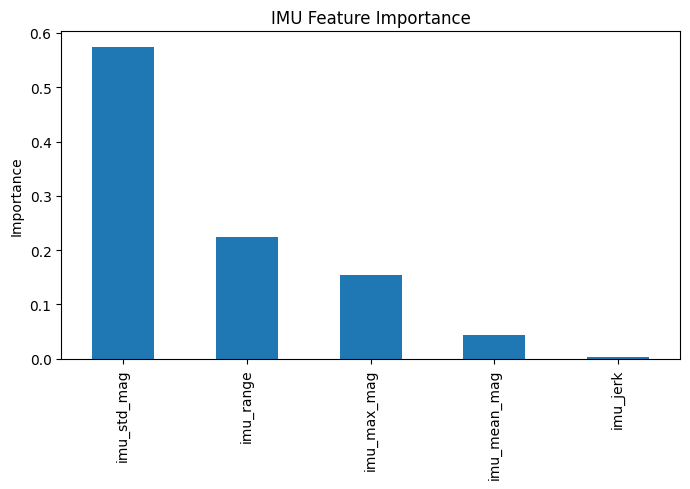


=== Value Ranges by CPOT Class ===
           imu_mean_mag                     imu_std_mag                      \
                    min       max      mean         min       max      mean   
cpot_class                                                                    
Low            0.012325  2.148145  0.377580    0.000000  0.215268  0.132994   
Moderate       0.120458  1.995068  0.707905    0.215305  0.463330  0.319673   
High           0.151105  6.065929  1.411347    0.463425  3.408162  0.848354   

           imu_max_mag                      imu_range                       \
                   min        max      mean       min        max      mean   
cpot_class                                                                   
Low           0.031561   2.152254  0.756829  0.000000   2.003245  0.619139   
Moderate      0.687970   4.786791  1.536328  0.628692   4.782614  1.376385   
High          1.311633  19.577942  3.472097  1.246232  19.500726  3.274634   

            imu_jerk

/tmp/ipykernel_2574/2636577578.py:134: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(feature_df.groupby('cpot_class').agg(['min', 'max', 'mean']))


In [ ]:
# ============================================================
# IMU - RANDOM FOREST (corrected: 3-class, balanced via quantiles)
# ============================================================

import zipfile, os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

# ---------------- Step 1: Extract zip ----------------
zip_path = "/content/imu_data1.zip"
extract_dir = "/content/imu_data"
os.makedirs(extract_dir, exist_ok=True)

print(f"Extracting: {zip_path} to {extract_dir}")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_dir)

csv_files = glob.glob(os.path.join(extract_dir, "**", "*.csv"), recursive=True)
print(f"Found CSV files: {csv_files}")

# ---------------- Step 2: Load and combine ----------------
dfs = [pd.read_csv(f) for f in csv_files]
df = pd.concat(dfs, ignore_index=True)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Use the wrist rotation rate columns (same as your original pipeline)
imu_cols = ['wristMotion_rotationRateX', 'wristMotion_rotationRateY', 'wristMotion_rotationRateZ']
imu_cols = [c for c in imu_cols if c in df.columns]
print(f"Using IMU columns: {imu_cols}")

df = df.dropna(subset=imu_cols)

# ---------------- Step 3: Windowing ----------------
WINDOW_SIZE = 128
STEP = 64

def window_signal(data, window_size=128, step=64):
    windows = []
    for start in range(0, len(data) - window_size, step):
        windows.append(data[start:start + window_size])
    return np.array(windows)

signal_data = df[imu_cols].values
windows = window_signal(signal_data, WINDOW_SIZE, STEP)
print(f"Total windows: {windows.shape}")

# ---------------- Step 4: Feature extraction ----------------
def extract_imu_features(window):
    # window shape: (timesteps, 3) -> X, Y, Z rotation rates
    magnitude = np.sqrt((window ** 2).sum(axis=1))
    jerk = np.diff(magnitude)  # rate of change of magnitude

    feats = {
        "imu_mean_mag": np.mean(magnitude),
        "imu_std_mag":  np.std(magnitude),
        "imu_max_mag":  np.max(magnitude),
        "imu_range":    np.max(magnitude) - np.min(magnitude),
        "imu_jerk":     np.mean(np.abs(jerk)) if len(jerk) > 0 else 0,
    }
    return feats

feature_rows = [extract_imu_features(w) for w in windows]
feature_df = pd.DataFrame(feature_rows)
print(feature_df.head())

# ---------------- Step 5: CPOT class labeling (FIXED — quantile-based) ----------------
# Old approach used a fixed threshold -> almost everything fell into "Low",
# causing severe class imbalance. Quantile-based splitting guarantees three
# roughly equal-sized groups, matching how sEMG/GSR were labeled.
feature_df['cpot_class'] = pd.qcut(
    feature_df['imu_std_mag'],   # highest feature importance in earlier run
    q=3,
    labels=['Low', 'Moderate', 'High']
)

print("\nClass distribution:")
print(feature_df['cpot_class'].value_counts())

# ---------------- Step 6: Train/test split ----------------
X = feature_df.drop(columns=['cpot_class'])
y = feature_df['cpot_class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ---------------- Step 7: Train Random Forest ----------------
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

# 5-fold cross-validation (matches your earlier output style)
cv_scores = cross_val_score(model, X, y, cv=5)
print(f"\n5-Fold Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# ---------------- Step 8: Evaluate ----------------
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\n=== IMU Model Accuracy (holdout): {acc:.4f} ===")
print(classification_report(y_test, y_pred))

# ---------------- Step 9: Confusion matrix ----------------
labels_order = ['Low', 'Moderate', 'High']
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_order, yticklabels=labels_order)
plt.title("IMU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------------- Step 10: Feature importance ----------------
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n=== Feature Importance ===")
print(importances)

plt.figure(figsize=(7, 5))
importances.plot(kind="bar")
plt.title("IMU Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# ---------------- Step 11: Value ranges by CPOT class ----------------
print("\n=== Value Ranges by CPOT Class ===")
print(feature_df.groupby('cpot_class').agg(['min', 'max', 'mean']))

# ---------------- Step 12: Save model ----------------
joblib.dump(model, "imu_model.pkl")
print("\nSaved: imu_model.pkl")